<a href="https://colab.research.google.com/github/ngtakwa/entwfinmaths/blob/main/P2P_BF_vs_AF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


SEC. 6.1: PRE-EXPANSION BENCHMARK AMONG INCUMBENTS ONLY

Pre-expansion summary:


,fairness,status,total_variance,var_inc_1,autarky_inc_1,IR_inc_1,var_inc_2,autarky_inc_2,IR_inc_2,var_inc_3,autarky_inc_3,IR_inc_3
0,AF,optimal,3.950000,0.750000,1.0,True,1.250000,2.25,True,1.950000,8.0,True
1,BF,optimal,3.952083,0.731163,1.0,True,1.276997,2.25,True,1.943924,8.0,True



------------------------------------------------------------------------------------------
Pre-expansion allocation matrix under AF:
[[0.133333 0.2      0.283333]
 [0.333333 0.333333 0.333333]
 [0.533333 0.466667 0.383333]]
Pre-expansion incumbent variances under AF:
[0.75 1.25 1.95]
Pre-expansion total variance under AF: 3.950000

------------------------------------------------------------------------------------------
Pre-expansion allocation matrix under BF:
[[0.129167 0.211111 0.277083]
 [0.316667 0.336111 0.339583]
 [0.554167 0.452778 0.383333]]
Pre-expansion incumbent variances under BF:
[0.731163 1.276997 1.943924]
Pre-expansion total variance under BF: 3.952083

SEC. 6.2 BASELINE POST-EXPANSION COMPARISON AT rho = 0.0

Post-expansion baseline summary:


,scheme,fairness,rho,status,total_variance,WC,SC,post_var_1,post_var_2,post_var_3,post_var_4,post_var_5,pre_benchmark_inc_1,pre_benchmark_inc_2,pre_benchmark_inc_3,inc_1_SC_ok,inc_2_SC_ok,inc_3_SC_ok
0,I,AF,0.0,optimal,6.254824,True,True,0.265890,0.356963,0.484464,4.569057,0.578450,0.750000,1.250000,1.950000,True,True,True
1,I,BF,0.0,optimal,6.336310,True,True,0.191569,0.330246,0.592443,4.644805,0.577247,0.731163,1.276997,1.943924,True,True,True
2,II,AF,0.0,optimal,7.702568,True,True,0.072858,0.163930,0.291431,5.582477,1.591871,0.750000,1.250000,1.950000,True,True,True
3,II,BF,0.0,optimal,8.133018,True,True,0.076316,0.166647,0.301125,6.951086,0.637844,0.731163,1.276997,1.943924,True,True,True



------------------------------------------------------------------------------------------
Post-expansion allocation matrix: Scheme I, AF, rho = 0.0
[[0.060842 0.107228 0.16521  0.045932 0.039968]
 [0.09727  0.131514 0.174318 0.086264 0.081861]
 [0.133699 0.1558   0.183425 0.126596 0.123754]
 [0.552632 0.435088 0.288158 0.590414 0.605527]
 [0.155557 0.170371 0.188889 0.150795 0.14889 ]]
Post-expansion variances: Scheme I, AF, rho = 0.0
[0.26589  0.356963 0.484464 4.569057 0.57845 ]
Total variance: 6.254824

------------------------------------------------------------------------------------------
Post-expansion allocation matrix: Scheme I, BF, rho = 0.0
[[0.022151 0.071176 0.13534  0.065106 0.041666]
 [0.106765 0.127586 0.163545 0.084663 0.095057]
 [0.27068  0.21806  0.197473 0.08115  0.164511]
 [0.504573 0.437424 0.314455 0.599217 0.57237 ]
 [0.095831 0.145754 0.189187 0.169865 0.126397]]
Post-expansion variances: Scheme I, BF, rho = 0.0
[0.191569 0.330246 0.592443 4.644805 0.577247]

Scheme_I_AF: 379 solved rho points


... (2 outputs left out)

Scheme_II_BF: 379 solved rho points

WC AND WC-BUT-NOT-SC RHO REGIONS


,scheme,fairness,WC_rho_min,WC_rho_max,WC_count,WC_not_SC_rho_min,WC_not_SC_rho_max,WC_not_SC_count
0,I,AF,-0.404166,0.354504,316,0.303265,0.354504,66
1,I,BF,-0.404166,0.386035,356,0.343468,0.386035,55
2,II,AF,-0.404166,0.073074,95,NaN,NaN,0
3,II,BF,-0.404166,0.001996,81,NaN,NaN,0



DETAIL: WHICH INCUMBENT FAILS SC WHEN WC HOLDS?


,scheme,fairness,rho_min,rho_max,count,inc_1_fail_count,inc_2_fail_count,inc_3_fail_count
0,I,AF,0.303265,0.354504,66,66,0,0
1,I,BF,0.343468,0.386035,55,55,26,0


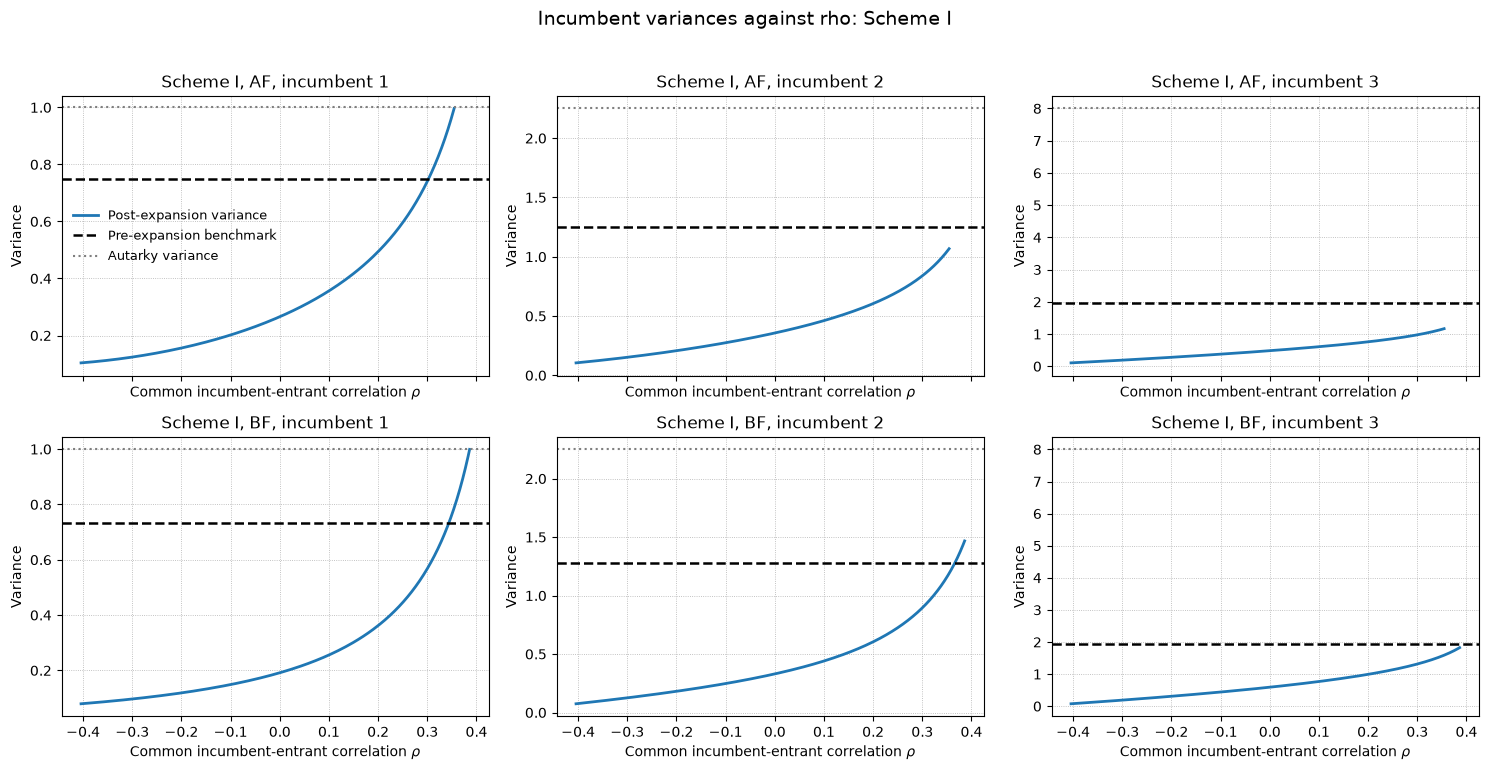

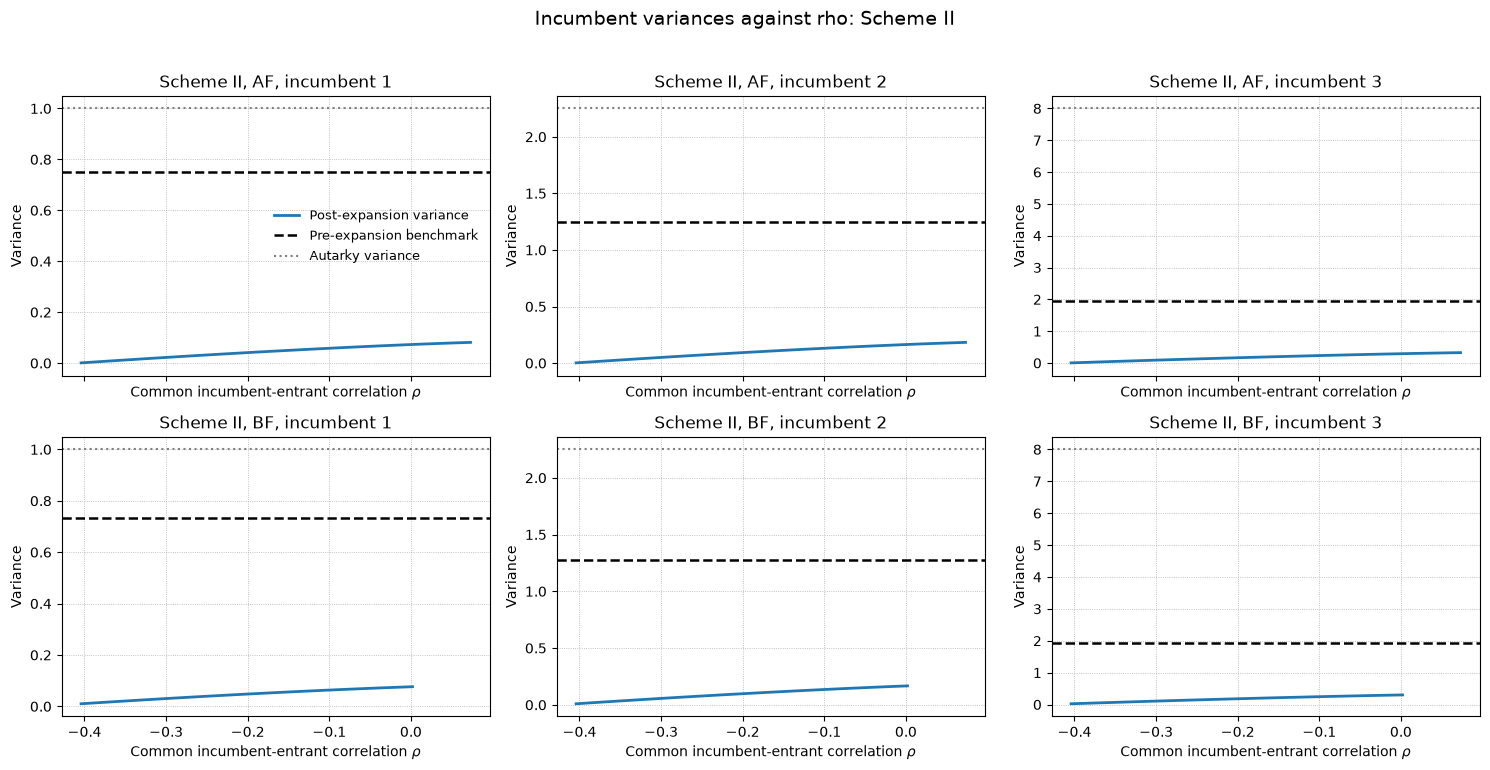

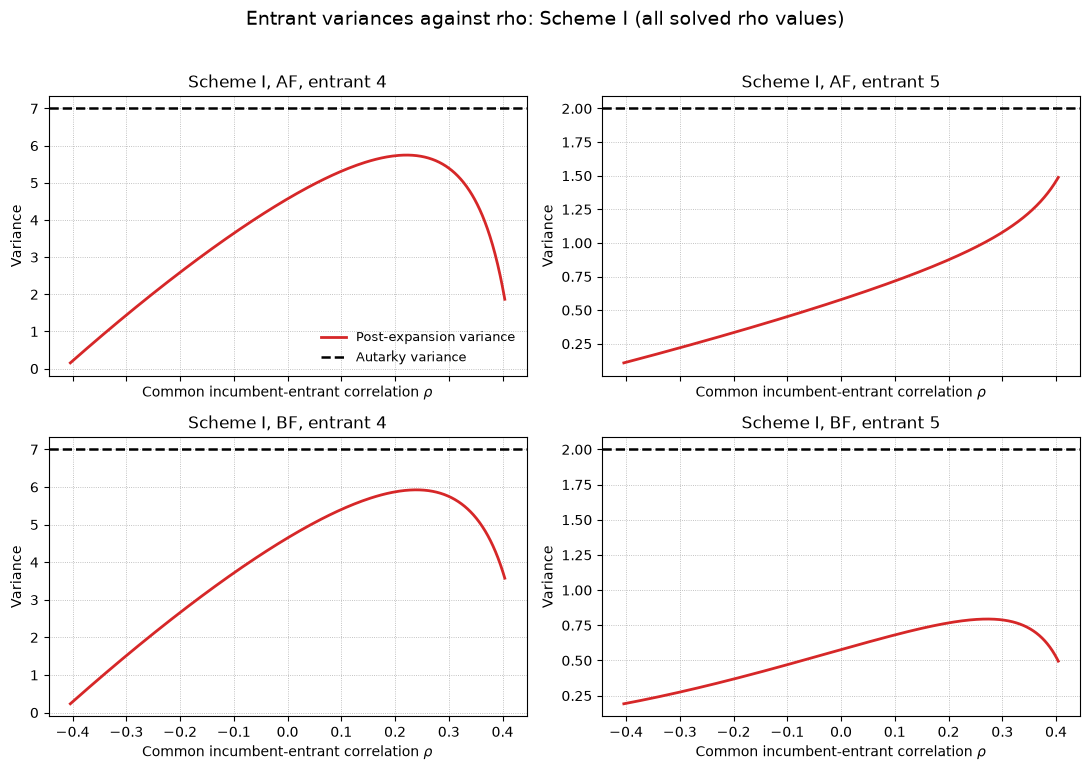

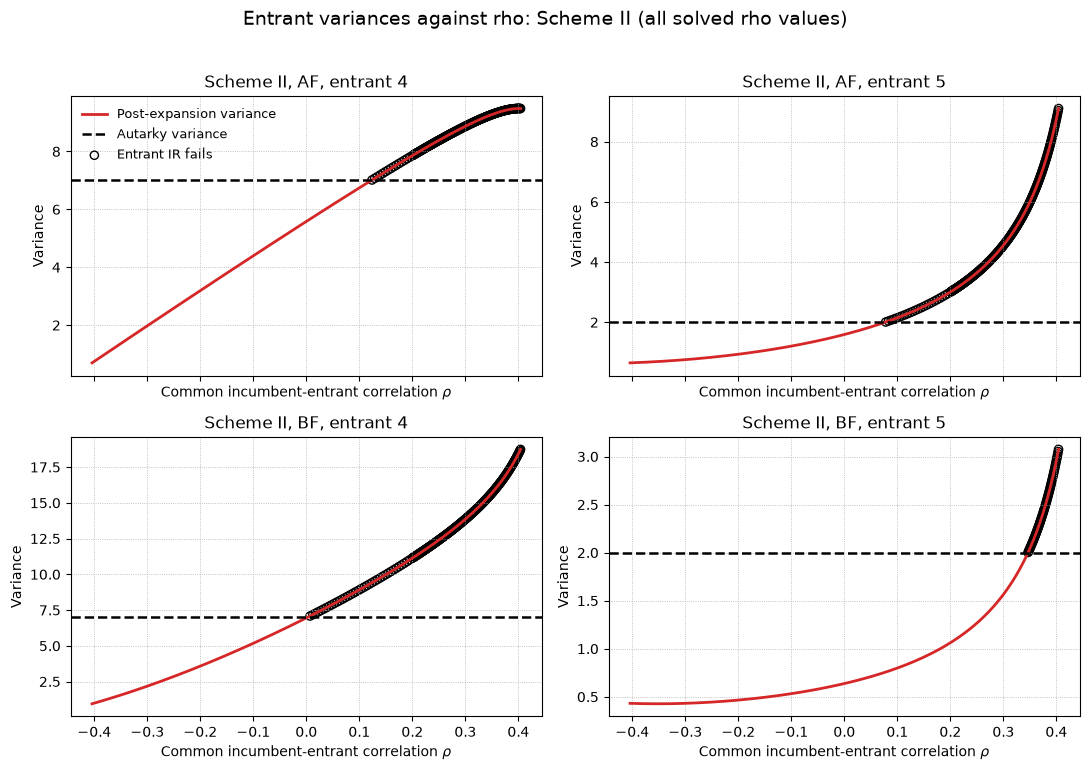

In [1]:
# ============================================================
# Numerical analysis for Sec. 6.1 and Sec. 6.2
# Baseline parameters:
# MU    = [1.0, 1.5, 2.0, 7.75, 2.3]
# VAR   = [1.0, 2.25, 8.0, 7, 2]
# I     = [0, 1, 2] I for incumbents
# E     = [3, 4] E for entrants
#
# Outputs:
# 1. Sec. 6.1: Pre-expansion 3-incumbent benchmark under AF and BF.
# 2. Sec. 6.2: Post-expansion baseline comparison under Scheme I/II and AF/BF.
# 3. Rho-change analysis: line plots of incumbent variances against rho,
#    with pre-expansion benchmark shown as a horizontal line.
# ============================================================

import numpy as np
import pandas as pd
import cvxpy as cp
import matplotlib.pyplot as plt

# Optional: cleaner printing
np.set_printoptions(precision=6, suppress=True)
pd.set_option("display.precision", 6)
pd.set_option("display.max_columns", 100)


# ============================================================
# 0. Parameter setting
# ============================================================

MU = np.array([1.0, 1.5, 2.0, 7.75, 2.3])
#MU = np.array([1.0, 1, 1, 1, 1])
VAR = np.array([1.0, 2.25, 8.0, 7, 2])
#VAR = np.array([1.0, 1, 1, 1, 1])

I = np.array([0, 1, 2])   # incumbents, Python indices
E = np.array([3, 4])      # entrants, Python indices

# Equal weights unless otherwise specified
w_inc = np.ones(len(I))
w_ent = np.ones(len(E))

# For Scheme II, entrant relative weights in the second-stage lexicographic problem
v_ent = np.ones(len(E))

# Numerical tolerance
TOL = 1e-7


# ============================================================
# 1. Utility functions
# ============================================================

def make_sigma_common_cross(VAR, I, E, rho):
    """
    Construct covariance matrix.
    Diagonal variances are fixed.
    Incumbent-entrant correlations are all set equal to rho.
    Other off-diagonal correlations are set to zero.
    """
    n = len(VAR)
    Sigma = np.diag(VAR).astype(float)

    for i in I:
        for j in E:
            cov_ij = rho * np.sqrt(VAR[i] * VAR[j])
            Sigma[i, j] = cov_ij
            Sigma[j, i] = cov_ij

    return Sigma


def is_psd(M, tol=1e-9):
    return np.min(np.linalg.eigvalsh(M)) >= -tol


def is_pd(M, tol=1e-9):
    return np.min(np.linalg.eigvalsh(M)) > tol


def member_variances(A, Sigma):
    """
    Variance of each member's post-exchange risk:
    diag(A Sigma A^T).
    """
    return np.diag(A @ Sigma @ A.T)


def check_wc(post_vars, autarky_vars, tol=TOL):
    """
    Weak consensus:
    every member's post-expansion variance is no larger than autarky.
    """
    return np.all(post_vars <= autarky_vars + tol)


def check_sc(post_vars, pre_inc_vars, I, E, autarky_vars, tol=TOL):
    """
    Strong consensus:
    incumbents are weakly better than pre-expansion,
    entrants are weakly better than autarky.
    """
    inc_ok = np.all(post_vars[I] <= pre_inc_vars + tol)
    ent_ok = np.all(post_vars[E] <= autarky_vars[E] + tol)
    return inc_ok and ent_ok


def solve_checked(problem, solver_primary, context):
    """Accept only optimal, finite solutions satisfying every constraint."""
    failures = []
    for solver in dict.fromkeys([solver_primary, "SCS"]):
        options = {"eps": 1e-8, "max_iters": 100000} if solver == "SCS" else {}
        try:
            problem.solve(solver=solver, **options)
        except cp.error.SolverError as err:
            failures.append(f"{solver}: {err}")
            continue

        if problem.status != cp.OPTIMAL:
            failures.append(f"{solver}: status={problem.status}")
            continue
        if (
            problem.value is None
            or not np.isfinite(problem.value)
            or any(v.value is None or not np.all(np.isfinite(v.value))
                   for v in problem.variables())
        ):
            failures.append(f"{solver}: non-finite solution")
            continue

        residual = max(float(np.max(c.violation())) for c in problem.constraints)
        if not np.isfinite(residual) or residual > TOL:
            failures.append(f"{solver}: constraint violation={residual:.3g}")
            continue
        return

    raise RuntimeError(f"{context} failed: " + "; ".join(failures))


def solve_allocation(
    MU,
    Sigma,
    fairness="BF",
    scheme="I",
    I=None,
    E=None,
    w_inc=None,
    w_ent=None,
    solver_primary="CLARABEL",
):
    """
    Solve the risk-sharing allocation.

    fairness:
        "AF": actuarial fairness, A @ MU = MU
        "BF": bilateral fairness, A @ M = M @ A.T

    scheme:
        "I": one-stage weighted-sum variance minimization.
        "II": lexicographic optimization:
              first incumbents, then entrants; requires positive-definite
              Sigma and strictly positive incumbent weights.

    Market clearing:
        sum_i a_ij = 1 for every j,
        implemented as cp.sum(A, axis=0) == np.ones(n).
    """
    n = len(MU)

    if I is None:
        I = np.arange(n)
    if E is None:
        E = np.array([], dtype=int)

    I = np.array(I, dtype=int)
    E = np.array(E, dtype=int)

    if w_inc is None:
        w_inc = np.ones(len(I))
    if w_ent is None:
        w_ent = np.ones(len(E))

    A = cp.Variable((n, n))

    constraints = []

    # Market clearing: column sums equal 1.
    constraints.append(cp.sum(A, axis=0) == np.ones(n))

    # Fairness constraint
    fairness = fairness.upper()
    if fairness == "AF":
        constraints.append(A @ MU == MU)
    elif fairness == "BF":
        M = np.diag(MU)
        constraints.append(A @ M == M @ A.T)
    else:
        raise ValueError("fairness must be 'AF' or 'BF'.")

    Sigma_psd = cp.psd_wrap(Sigma)
    var_expr = [cp.quad_form(A[i, :], Sigma_psd) for i in range(n)]

    scheme = scheme.upper()

    if scheme == "I":
        obj = 0
        for k, i in enumerate(I):
            obj += w_inc[k] * var_expr[i]
        for k, j in enumerate(E):
            obj += w_ent[k] * var_expr[j]

        prob = cp.Problem(cp.Minimize(obj), constraints)

        solve_checked(prob, solver_primary, "Scheme I")

        return A.value, prob.value, prob.status

    elif scheme == "II":
        if len(E) == 0:
            raise ValueError("Scheme II requires a nonempty entrant set E.")
        if not is_pd(Sigma) or not np.all(np.asarray(w_inc) > 0):
            raise ValueError(
                "Scheme II requires positive-definite Sigma and positive incumbent weights."
            )

        # Stage 1: minimize incumbents' weighted-sum variance
        obj_inc = 0
        for k, i in enumerate(I):
            obj_inc += w_inc[k] * var_expr[i]

        prob1 = cp.Problem(cp.Minimize(obj_inc), constraints)

        solve_checked(prob1, solver_primary, "Scheme II stage 1")
        incumbent_rows = A.value[I, :].copy()

        # Stage 2: among stage-1 minimizers, minimize entrants' weighted-sum variance
        obj_ent = 0
        for k, j in enumerate(E):
            obj_ent += w_ent[k] * var_expr[j]

        # Strict convexity makes the incumbent rows identical at all stage-1
        # minimizers. Fixing these rows implements exact lexicographic priority
        # with affine constraints, avoiding a nearly tight quadratic constraint.
        constraints2 = constraints + [A[I, :] == incumbent_rows]

        prob2 = cp.Problem(cp.Minimize(obj_ent), constraints2)

        solve_checked(prob2, solver_primary, "Scheme II stage 2")

        return A.value, prob2.value, prob2.status

    else:
        raise ValueError("scheme must be 'I' or 'II'.")


# ============================================================
# 2. Sec. 6.1: Pre-expansion 3-incumbent benchmark
# ============================================================

def compute_pre_expansion_results(MU, VAR, I, w_inc):
    """
    Compute pre-expansion risk-sharing among incumbents only.
    This gives the benchmark for SC in Sec. 6.2.
    """
    MU_pre = MU[I]
    Sigma_pre = np.diag(VAR[I])

    records = []
    A_pre_dict = {}
    pre_var_dict = {}

    for fairness in ["AF", "BF"]:
        A_pre, obj, status = solve_allocation(
            MU=MU_pre,
            Sigma=Sigma_pre,
            fairness=fairness,
            scheme="I",
            I=np.arange(len(I)),
            E=np.array([], dtype=int),
            w_inc=w_inc,
            w_ent=np.array([]),
        )

        pre_vars = member_variances(A_pre, Sigma_pre)
        autarky_vars = np.diag(Sigma_pre)

        A_pre_dict[fairness] = A_pre
        pre_var_dict[fairness] = pre_vars

        rec = {
            "fairness": fairness,
            "status": status,
            "total_variance": np.sum(pre_vars),
        }

        for idx in range(len(I)):
            rec[f"var_inc_{idx+1}"] = pre_vars[idx]
            rec[f"autarky_inc_{idx+1}"] = autarky_vars[idx]
            rec[f"IR_inc_{idx+1}"] = pre_vars[idx] <= autarky_vars[idx] + TOL

        records.append(rec)

    summary = pd.DataFrame(records)

    return A_pre_dict, pre_var_dict, summary


A_pre_dict, pre_var_dict, pre_summary = compute_pre_expansion_results(
    MU=MU,
    VAR=VAR,
    I=I,
    w_inc=w_inc,
)

print("\n" + "=" * 90)
print("SEC. 6.1: PRE-EXPANSION BENCHMARK AMONG INCUMBENTS ONLY")
print("=" * 90)

print("\nPre-expansion summary:")
display(pre_summary)

for fairness in ["AF", "BF"]:
    print("\n" + "-" * 90)
    print(f"Pre-expansion allocation matrix under {fairness}:")
    print(np.round(A_pre_dict[fairness], 6))
    print(f"Pre-expansion incumbent variances under {fairness}:")
    print(np.round(pre_var_dict[fairness], 6))
    print(f"Pre-expansion total variance under {fairness}: {np.sum(pre_var_dict[fairness]):.6f}")


# ============================================================
# 3. Sec. 6.2 baseline: Post-expansion comparison at rho = 0
# ============================================================

def compute_post_expansion_baseline(MU, VAR, I, E, w_inc, w_ent, rho0=0.0):
    Sigma_full = make_sigma_common_cross(VAR, I, E, rho0)
    autarky_vars = np.diag(Sigma_full)

    records = []
    A_post_dict = {}
    post_var_dict = {}

    for scheme in ["I", "II"]:
        for fairness in ["AF", "BF"]:
            A_post, obj, status = solve_allocation(
                MU=MU,
                Sigma=Sigma_full,
                fairness=fairness,
                scheme=scheme,
                I=I,
                E=E,
                w_inc=w_inc,
                w_ent=w_ent,
            )

            post_vars = member_variances(A_post, Sigma_full)
            pre_vars = pre_var_dict[fairness]

            WC = check_wc(post_vars, autarky_vars)
            SC = check_sc(post_vars, pre_vars, I, E, autarky_vars)

            A_post_dict[(scheme, fairness)] = A_post
            post_var_dict[(scheme, fairness)] = post_vars

            rec = {
                "scheme": scheme,
                "fairness": fairness,
                "rho": rho0,
                "status": status,
                "total_variance": np.sum(post_vars),
                "WC": WC,
                "SC": SC,
            }

            for i in range(len(MU)):
                rec[f"post_var_{i+1}"] = post_vars[i]
                rec[f"autarky_{i+1}"] = autarky_vars[i]
                rec[f"IR_{i+1}"] = post_vars[i] <= autarky_vars[i] + TOL

            for idx, inc in enumerate(I):
                rec[f"pre_benchmark_inc_{inc+1}"] = pre_vars[idx]
                rec[f"inc_{inc+1}_SC_ok"] = post_vars[inc] <= pre_vars[idx] + TOL

            records.append(rec)

    summary = pd.DataFrame(records)

    return A_post_dict, post_var_dict, summary


rho0 = 0.0

A_post_dict, post_var_dict, post_summary = compute_post_expansion_baseline(
    MU=MU,
    VAR=VAR,
    I=I,
    E=E,
    w_inc=w_inc,
    w_ent=w_ent,
    rho0=rho0,
)

print("\n" + "=" * 90)
print(f"SEC. 6.2 BASELINE POST-EXPANSION COMPARISON AT rho = {rho0}")
print("=" * 90)

display_cols = [
    "scheme", "fairness", "rho", "status",
    "total_variance", "WC", "SC",
    "post_var_1", "post_var_2", "post_var_3", "post_var_4", "post_var_5",
    "pre_benchmark_inc_1", "pre_benchmark_inc_2", "pre_benchmark_inc_3",
    "inc_1_SC_ok", "inc_2_SC_ok", "inc_3_SC_ok",
]

print("\nPost-expansion baseline summary:")
display(post_summary[display_cols])

for scheme in ["I", "II"]:
    for fairness in ["AF", "BF"]:
        print("\n" + "-" * 90)
        print(f"Post-expansion allocation matrix: Scheme {scheme}, {fairness}, rho = {rho0}")
        print(np.round(A_post_dict[(scheme, fairness)], 6))

        print(f"Post-expansion variances: Scheme {scheme}, {fairness}, rho = {rho0}")
        print(np.round(post_var_dict[(scheme, fairness)], 6))

        print(f"Total variance: {np.sum(post_var_dict[(scheme, fairness)]):.6f}")


# ============================================================
# 4. Rho experiment
# ============================================================

def run_rho_experiment(
    MU,
    VAR,
    I,
    E,
    scheme,
    fairness,
    rho_grid,
    w_inc,
    w_ent,
):
    """
    For each rho:
    - construct Sigma(rho);
    - solve post-expansion allocation;
    - compute variances, WC, SC;
    - store results.

    Pre-expansion benchmark is fixed because only incumbent-entrant
    correlations are varied.
    """
    records = []

    pre_vars = pre_var_dict[fairness]

    for rho in rho_grid:
        Sigma = make_sigma_common_cross(VAR, I, E, rho)

        if not is_psd(Sigma):
            continue

        try:
            A_post, obj, status = solve_allocation(
                MU=MU,
                Sigma=Sigma,
                fairness=fairness,
                scheme=scheme,
                I=I,
                E=E,
                w_inc=w_inc,
                w_ent=w_ent,
            )
        except Exception as err:
            raise RuntimeError(
                f"Scheme {scheme}, {fairness}, rho={rho:.12g}: {err}"
            ) from err

        post_vars = member_variances(A_post, Sigma)
        autarky_vars = np.diag(Sigma)

        WC = check_wc(post_vars, autarky_vars)
        SC = check_sc(post_vars, pre_vars, I, E, autarky_vars)

        rec = {
            "scheme": scheme,
            "fairness": fairness,
            "rho": rho,
            "status": status,
            "total_variance": np.sum(post_vars),
            "WC": WC,
            "SC": SC,
        }

        for i in range(len(MU)):
            rec[f"post_var_{i+1}"] = post_vars[i]
            rec[f"autarky_{i+1}"] = autarky_vars[i]
            rec[f"IR_{i+1}"] = post_vars[i] <= autarky_vars[i] + TOL

        for idx, inc in enumerate(I):
            rec[f"pre_benchmark_inc_{inc+1}"] = pre_vars[idx]
            rec[f"inc_{inc+1}_SC_ok"] = post_vars[inc] <= pre_vars[idx] + TOL

        records.append(rec)

    return pd.DataFrame(records)


# Common incumbent-entrant correlation feasibility:
# with 3 incumbents and 2 entrants, the correlation matrix is PSD only within
# approximately [-1/sqrt(6), 1/sqrt(6)].
rho_bound = 1 / np.sqrt(len(I) * len(E))

# Dense grid, especially useful near the upper end where WC-but-not-SC occurs.
rho_grid = np.concatenate([
    np.linspace(-0.99 * rho_bound, 0.20, 120),
    np.linspace(0.20, 0.99 * rho_bound, 260),
])
rho_grid = np.unique(np.round(rho_grid, 12))

print("\n" + "=" * 90)
print("RHO EXPERIMENT")
print("=" * 90)
print(f"Admissible approximate rho range: ({-rho_bound:.6f}, {rho_bound:.6f})")
print(f"Grid range used: [{rho_grid.min():.6f}, {rho_grid.max():.6f}]")
print(f"Number of rho grid points: {len(rho_grid)}")

rho_results = {}

for scheme in ["I", "II"]:
    for fairness in ["AF", "BF"]:
        key = f"Scheme_{scheme}_{fairness}"
        df = run_rho_experiment(
            MU=MU,
            VAR=VAR,
            I=I,
            E=E,
            scheme=scheme,
            fairness=fairness,
            rho_grid=rho_grid,
            w_inc=w_inc,
            w_ent=w_ent,
        )
        rho_results[key] = df
        print(f"{key}: {df.shape[0]} solved rho points")


# ============================================================
# 5. Summarize WC and WC-but-not-SC regions
# ============================================================

def summarize_regions(df):
    if df.empty:
        return {
            "WC_rho_min": np.nan,
            "WC_rho_max": np.nan,
            "WC_count": 0,
            "WC_not_SC_rho_min": np.nan,
            "WC_not_SC_rho_max": np.nan,
            "WC_not_SC_count": 0,
        }

    df_wc = df[df["WC"] == True]
    df_wc_not_sc = df[(df["WC"] == True) & (df["SC"] == False)]

    out = {}

    if len(df_wc) > 0:
        out["WC_rho_min"] = df_wc["rho"].min()
        out["WC_rho_max"] = df_wc["rho"].max()
        out["WC_count"] = len(df_wc)
    else:
        out["WC_rho_min"] = np.nan
        out["WC_rho_max"] = np.nan
        out["WC_count"] = 0

    if len(df_wc_not_sc) > 0:
        out["WC_not_SC_rho_min"] = df_wc_not_sc["rho"].min()
        out["WC_not_SC_rho_max"] = df_wc_not_sc["rho"].max()
        out["WC_not_SC_count"] = len(df_wc_not_sc)
    else:
        out["WC_not_SC_rho_min"] = np.nan
        out["WC_not_SC_rho_max"] = np.nan
        out["WC_not_SC_count"] = 0

    return out


region_rows = []

for scheme in ["I", "II"]:
    for fairness in ["AF", "BF"]:
        key = f"Scheme_{scheme}_{fairness}"
        info = summarize_regions(rho_results[key])
        info["scheme"] = scheme
        info["fairness"] = fairness
        region_rows.append(info)

region_summary = pd.DataFrame(region_rows)
region_summary = region_summary[
    [
        "scheme", "fairness",
        "WC_rho_min", "WC_rho_max", "WC_count",
        "WC_not_SC_rho_min", "WC_not_SC_rho_max", "WC_not_SC_count",
    ]
]

print("\n" + "=" * 90)
print("WC AND WC-BUT-NOT-SC RHO REGIONS")
print("=" * 90)
display(region_summary)


# Also print which incumbent fails SC inside the WC-but-not-SC region.
fail_rows = []

for scheme in ["I", "II"]:
    for fairness in ["AF", "BF"]:
        key = f"Scheme_{scheme}_{fairness}"
        df = rho_results[key]

        hits = df[(df["WC"] == True) & (df["SC"] == False)].copy()

        if len(hits) == 0:
            continue

        row = {
            "scheme": scheme,
            "fairness": fairness,
            "rho_min": hits["rho"].min(),
            "rho_max": hits["rho"].max(),
            "count": len(hits),
        }

        for inc in I:
            row[f"inc_{inc+1}_fail_count"] = np.sum(hits[f"inc_{inc+1}_SC_ok"] == False)

        fail_rows.append(row)

fail_summary = pd.DataFrame(fail_rows)

print("\n" + "=" * 90)
print("DETAIL: WHICH INCUMBENT FAILS SC WHEN WC HOLDS?")
print("=" * 90)

if len(fail_summary) > 0:
    display(fail_summary)
else:
    print("No WC-but-not-SC cases found.")


# ============================================================
# 6. Line plots: incumbent variance against rho
#    Plot only rho values where WC holds.
#    Pre-expansion benchmark is shown as a horizontal line.
# ============================================================

def plot_incumbent_variance_against_rho(
    rho_results,
    pre_var_dict,
    scheme,
    I,
    savefig=False,
    filename=None,
):
    """
    Produces one 2 x 3 figure for a fixed scheme:
    rows: AF, BF
    columns: incumbents 1, 2, 3

    Only rho values satisfying WC are plotted.
    The pre-expansion benchmark is shown as a horizontal dashed line.
    """
    fairness_list = ["AF", "BF"]

    fig, axes = plt.subplots(
        nrows=2,
        ncols=len(I),
        figsize=(15, 7.5),
        sharex=True,
    )

    for r, fairness in enumerate(fairness_list):
        key = f"Scheme_{scheme}_{fairness}"
        df = rho_results[key].copy()

        # Plotting range: only rho values where all members' IRs are satisfied, i.e. WC holds.
        df_wc = df[df["WC"] == True].copy()

        for c, inc in enumerate(I):
            ax = axes[r, c]
            inc_label = inc + 1

            if len(df_wc) == 0:
                ax.text(
                    0.5,
                    0.5,
                    "No WC region",
                    transform=ax.transAxes,
                    ha="center",
                    va="center",
                    fontsize=11,
                )
                ax.set_title(f"Scheme {scheme}, {fairness}, incumbent {inc_label}")
                ax.set_xlabel(r"$\rho$")
                ax.set_ylabel("Variance")
                ax.grid(True, linestyle=":", linewidth=0.6)
                continue

            x = df_wc["rho"].values
            y = df_wc[f"post_var_{inc_label}"].values

            pre_benchmark = pre_var_dict[fairness][c]

            # Post-expansion variance line
            ax.plot(
                x,
                y,
                color="tab:blue",
                linestyle="-",
                linewidth=2.0,
                label="Post-expansion variance",
            )

            # Pre-expansion horizontal benchmark
            ax.axhline(
                y=pre_benchmark,
                color="black",
                linestyle="--",
                linewidth=1.8,
                label="Pre-expansion benchmark",
            )

            # Optional visual reference: autarky variance
            # Comment this out if you want only two lines.
            ax.axhline(
                y=VAR[inc],
                color="tab:gray",
                linestyle=":",
                linewidth=1.5,
                label="Autarky variance",
            )

            ax.set_title(f"Scheme {scheme}, {fairness}, incumbent {inc_label}")
            ax.set_xlabel(r"Common incumbent-entrant correlation $\rho$")
            ax.set_ylabel("Variance")
            ax.grid(True, linestyle=":", linewidth=0.6)

            # This makes WC-but-not-SC visually identifiable:
            # within the WC plotting range, whenever the blue line is above
            # the dashed benchmark, that incumbent is worse off than pre-expansion.
            ymin, ymax = ax.get_ylim()
            ax.set_ylim(ymin, ymax)

            if r == 0 and c == 0:
                ax.legend(frameon=False, fontsize=9)

    fig.suptitle(
        f"Incumbent variances against rho: Scheme {scheme}",
        fontsize=14,
        y=1.02,
    )

    plt.tight_layout()

    if savefig:
        if filename is None:
            filename = f"scheme_{scheme}_incumbent_variances_against_rho.png"
        plt.savefig(filename, dpi=300, bbox_inches="tight")

    plt.show()


# Produce the two main figures:
# Figure 1: Scheme I, AF/BF, incumbents 1/2/3
# Figure 2: Scheme II, AF/BF, incumbents 1/2/3

plot_incumbent_variance_against_rho(
    rho_results=rho_results,
    pre_var_dict=pre_var_dict,
    scheme="I",
    I=I,
    savefig=False,
)

plot_incumbent_variance_against_rho(
    rho_results=rho_results,
    pre_var_dict=pre_var_dict,
    scheme="II",
    I=I,
    savefig=False,
)


# ============================================================
# 7. Entrant variance plots against rho
#    Entrants 4 and 5, with autarky variance benchmarks
# ============================================================

def plot_entrant_variance_against_rho(
    rho_results,
    E,
    VAR,
    plot_only_wc=False,
    savefig=False,
    filename=None,
):
    """
    Produces one 2 x 2 figure for each scheme:
        rows: AF, BF
        columns: entrants 4, 5

    Solid line:
        post-expansion entrant variance as rho changes.

    Horizontal dashed line:
        entrant's autarky variance.

    If plot_only_wc=True:
        only rho values satisfying WC are plotted.
    If plot_only_wc=False:
        all solved rho values are plotted, so that entrant IR failure
        can be visually identified when the solid line exceeds the
        dashed autarky line.
    """

    fairness_list = ["AF", "BF"]

    for scheme in ["I", "II"]:

        fig, axes = plt.subplots(
            nrows=2,
            ncols=len(E),
            figsize=(11, 7.5),
            sharex=True,
        )

        for r, fairness in enumerate(fairness_list):
            key = f"Scheme_{scheme}_{fairness}"
            df = rho_results[key].copy()

            if plot_only_wc:
                df_plot = df[df["WC"] == True].copy()
            else:
                df_plot = df.copy()

            for c, ent in enumerate(E):
                ax = axes[r, c]
                ent_label = ent + 1

                if len(df_plot) == 0:
                    ax.text(
                        0.5,
                        0.5,
                        "No data",
                        transform=ax.transAxes,
                        ha="center",
                        va="center",
                        fontsize=11,
                    )
                    ax.set_title(f"Scheme {scheme}, {fairness}, entrant {ent_label}")
                    ax.set_xlabel(r"$\rho$")
                    ax.set_ylabel("Variance")
                    ax.grid(True, linestyle=":", linewidth=0.6)
                    continue

                x = df_plot["rho"].values
                y = df_plot[f"post_var_{ent_label}"].values
                autarky_var = VAR[ent]

                # Post-expansion entrant variance
                ax.plot(
                    x,
                    y,
                    color="tab:red",
                    linestyle="-",
                    linewidth=2.0,
                    label="Post-expansion variance",
                )

                # Autarky benchmark
                ax.axhline(
                    y=autarky_var,
                    color="black",
                    linestyle="--",
                    linewidth=1.8,
                    label="Autarky variance",
                )

                # Mark entrant IR failure points, i.e. post variance > autarky
                ir_fail = df_plot[df_plot[f"post_var_{ent_label}"] > autarky_var + TOL]

                if len(ir_fail) > 0:
                    ax.scatter(
                        ir_fail["rho"],
                        ir_fail[f"post_var_{ent_label}"],
                        facecolors="none",
                        edgecolors="black",
                        marker="o",
                        s=35,
                        linewidth=1.0,
                        label="Entrant IR fails",
                    )

                ax.set_title(f"Scheme {scheme}, {fairness}, entrant {ent_label}")
                ax.set_xlabel(r"Common incumbent-entrant correlation $\rho$")
                ax.set_ylabel("Variance")
                ax.grid(True, linestyle=":", linewidth=0.6)

                if r == 0 and c == 0:
                    ax.legend(frameon=False, fontsize=9)

        if plot_only_wc:
            title_suffix = "WC region only"
        else:
            title_suffix = "all solved rho values"

        fig.suptitle(
            f"Entrant variances against rho: Scheme {scheme} ({title_suffix})",
            fontsize=14,
            y=1.02,
        )

        plt.tight_layout()

        if savefig:
            if filename is None:
                fname = f"scheme_{scheme}_entrant_variances_against_rho.png"
            else:
                fname = filename.replace(".png", f"_scheme_{scheme}.png")

            plt.savefig(fname, dpi=300, bbox_inches="tight")

        plt.show()


# ------------------------------------------------------------
# Produce entrant plots.
# Recommended default: plot_only_wc=False,
# because this shows directly where entrant IR fails.
# ------------------------------------------------------------

plot_entrant_variance_against_rho(
    rho_results=rho_results,
    E=E,
    VAR=VAR,
    plot_only_wc=False,
    savefig=False,
)

# If you want the same plotting convention as incumbent plots,
# i.e. restrict to rho values where WC holds, run this instead:
#
# plot_entrant_variance_against_rho(
#     rho_results=rho_results,
#     E=E,
#     VAR=VAR,
#     plot_only_wc=True,
#     savefig=False,
# )

Plotting allocation coefficients in this order:
['Member 1', 'Member 2', 'Member 3', 'Member 4', 'Member 5']

COLLECTING A(rho) COEFFICIENTS


Scheme_I_AF: stored 379 solved rho points


Scheme_I_BF: stored 379 solved rho points


Scheme_II_AF: stored 379 solved rho points


Scheme_II_BF: stored 379 solved rho points

PLOTTING a_ij(rho)


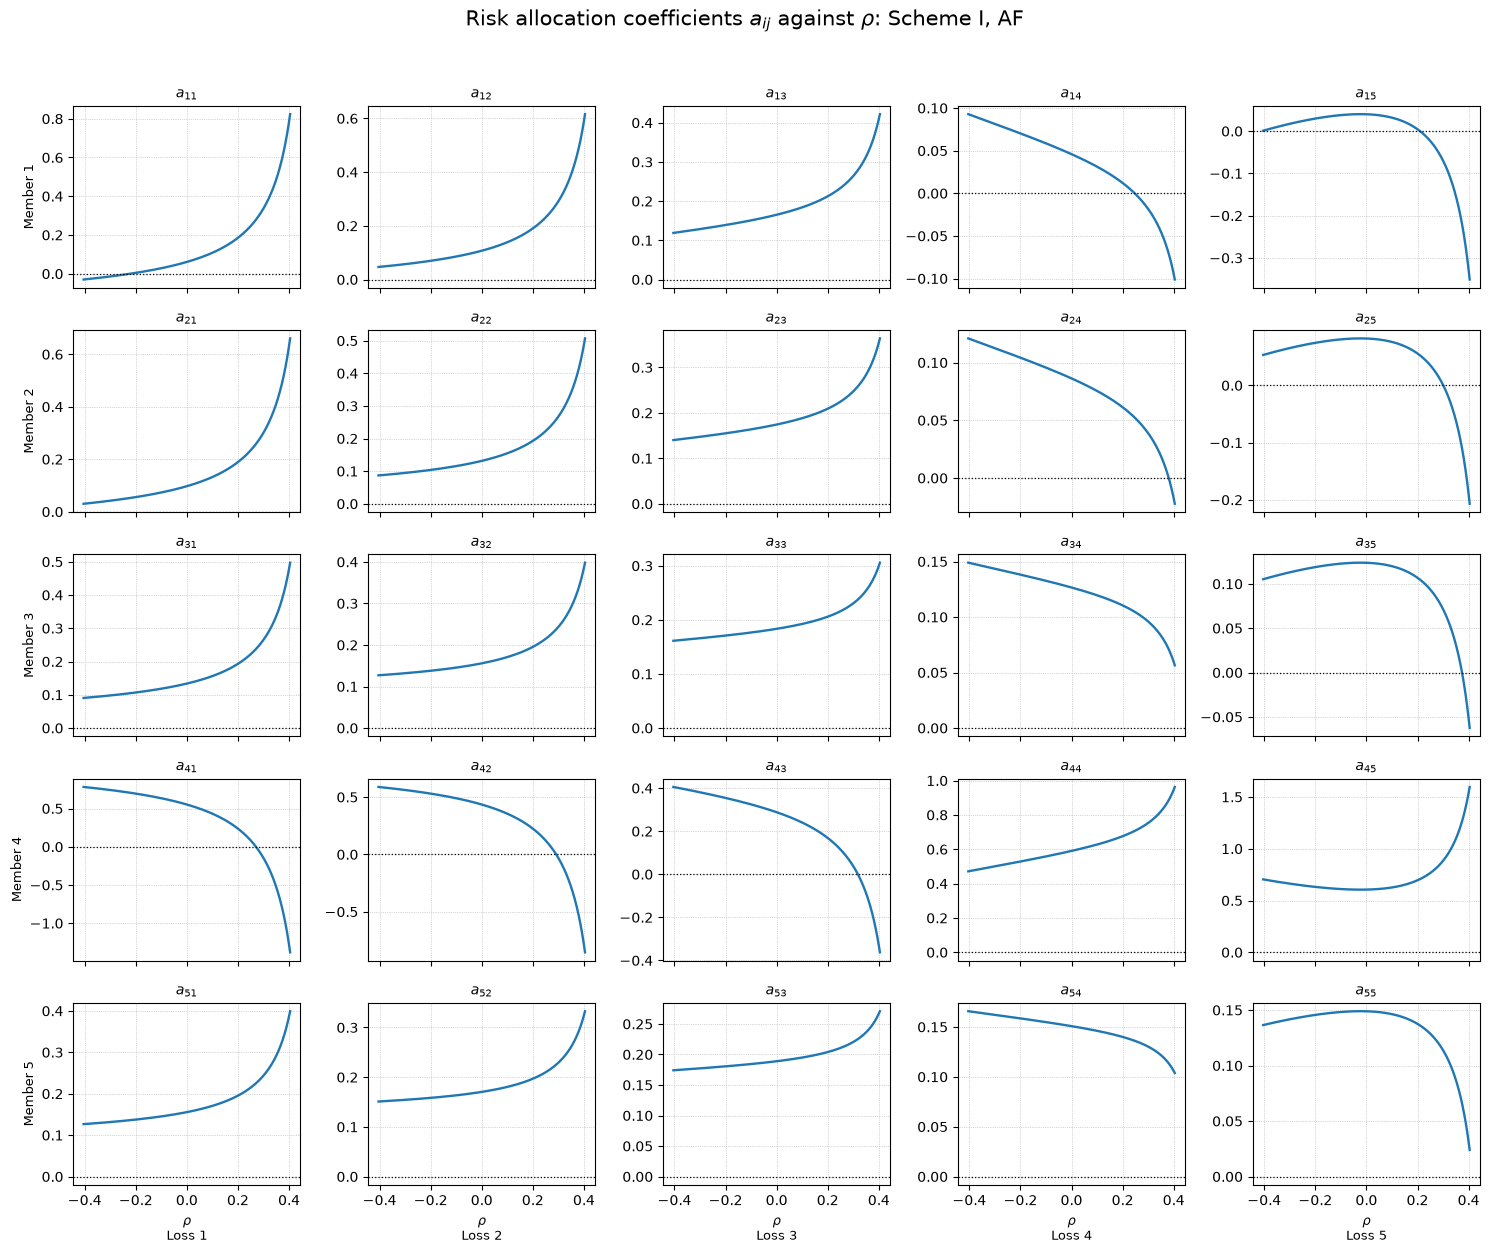

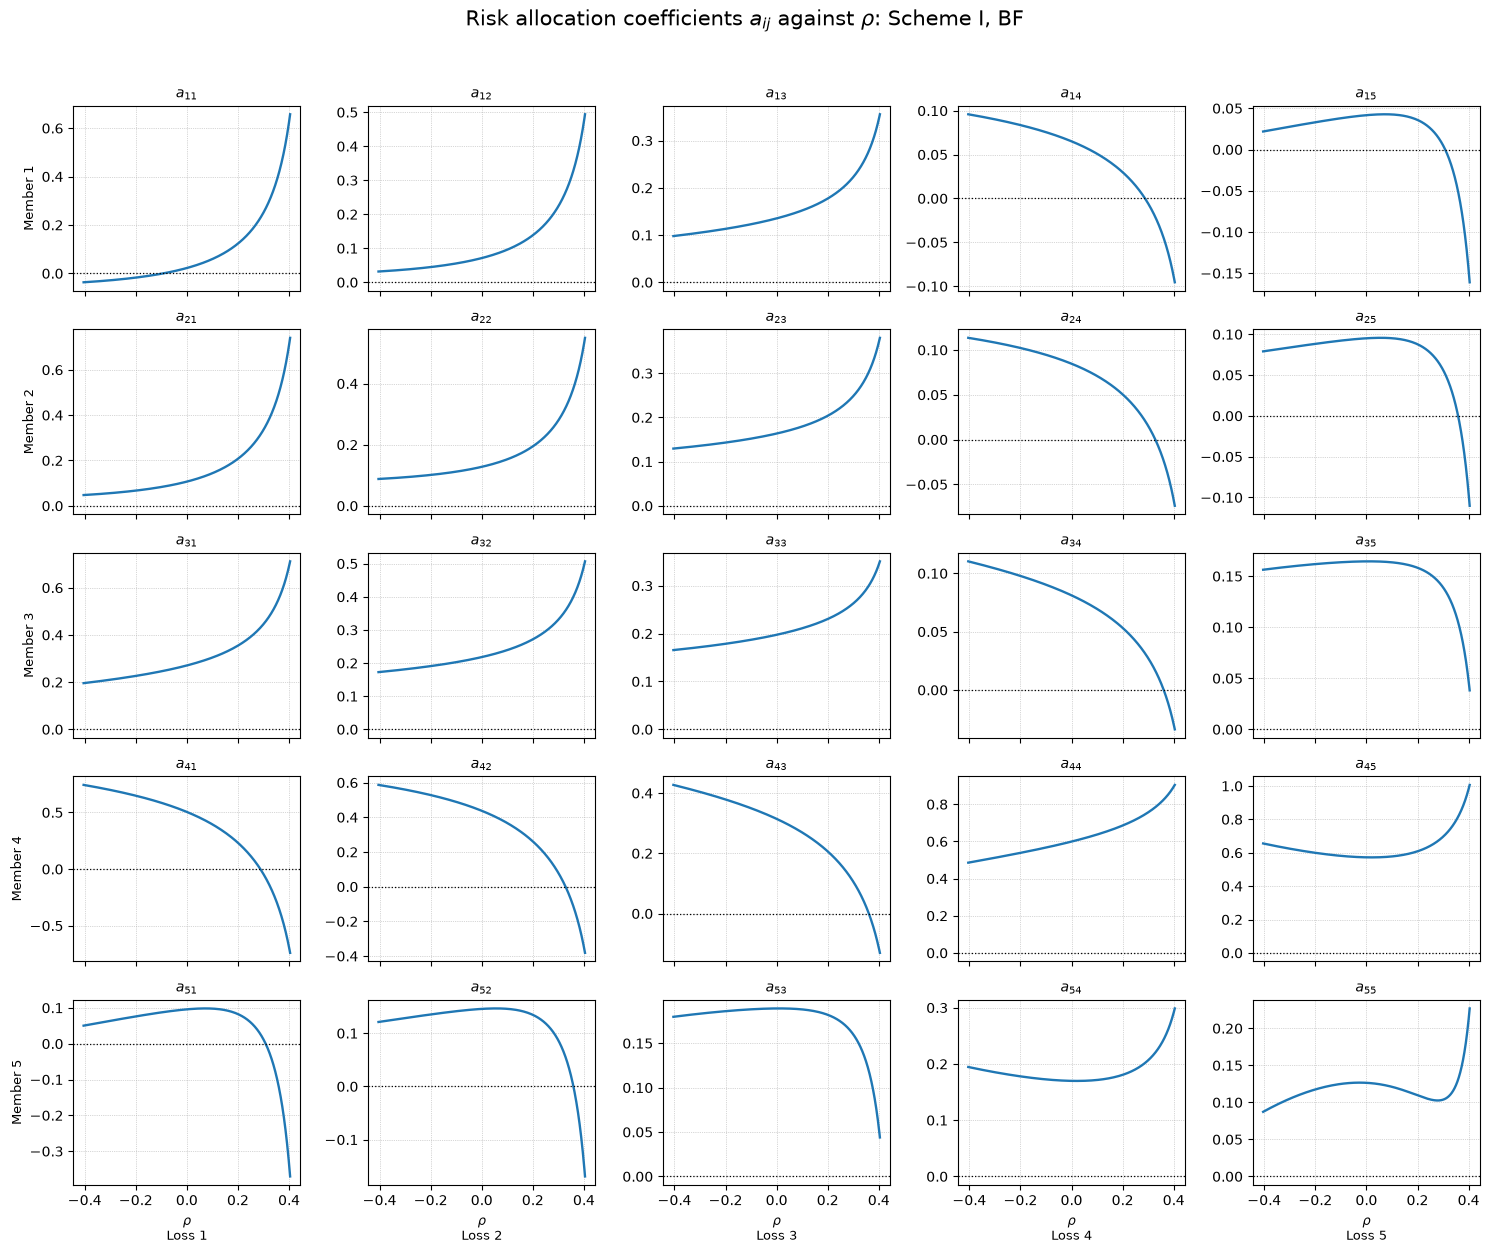

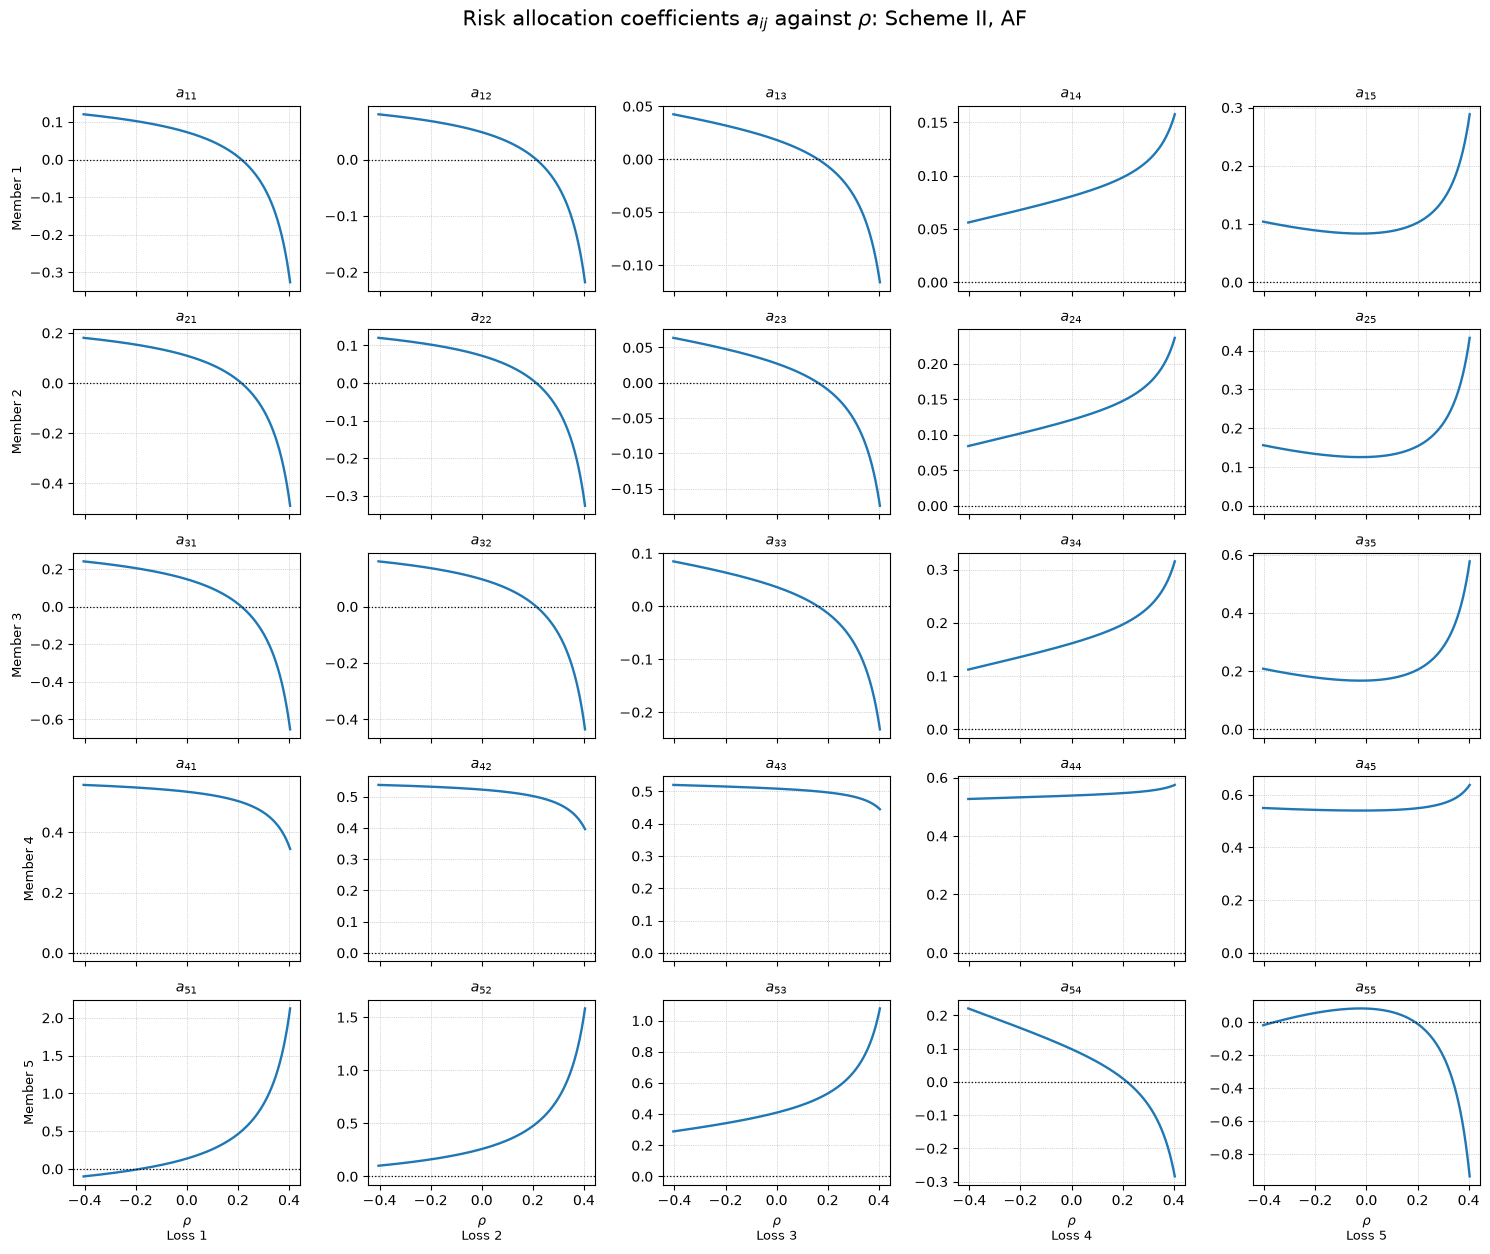

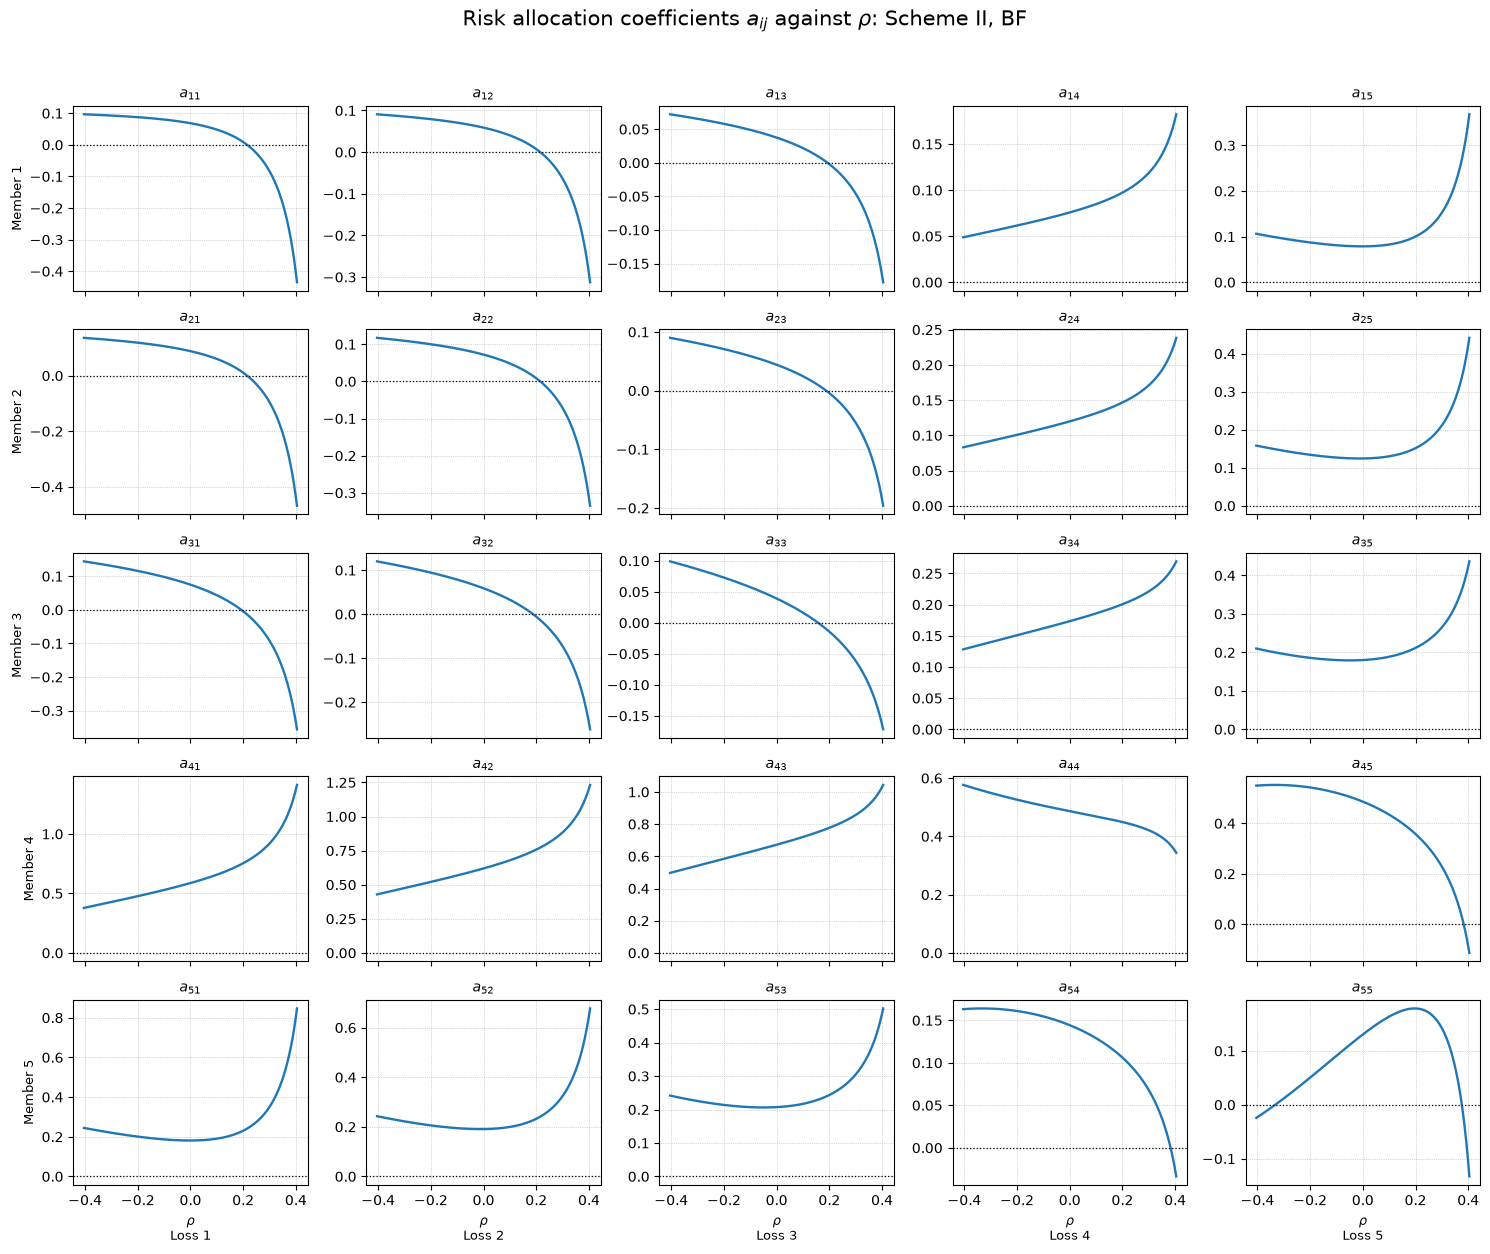

In [2]:
# ============================================================
# Allocation coefficient plots: a_ij against rho
# 2 entrants + 3 incumbents model
# ============================================================
#
# This block assumes the following objects/functions already exist:
#   MU, VAR, I, E
#   w_inc, w_ent
#   rho_grid
#   make_sigma_common_cross
#   is_psd
#   solve_allocation
#
# It recomputes A(rho), stores all a_ij, and plots each a_ij against rho.
# Members are ordered as incumbents first, then entrants.
# ============================================================

# ------------------------------------------------------------
# User controls
# ------------------------------------------------------------

SCHEME_LIST_FOR_A_PLOTS = ["I", "II"]
FAIRNESS_LIST_FOR_A_PLOTS = ["AF", "BF"]   # change to ["BF"] if needed

# If True, plot only rho values for which WC holds, using rho_results if available.
# If False, plot all solved PSD rho values.
PLOT_A_ONLY_WC = False

SAVE_A_FIGURES = False


# ------------------------------------------------------------
# Helper: order members as incumbents first, then entrants
# ------------------------------------------------------------

member_order = list(I) + list(E)
member_labels_ordered = [f"Member {i+1}" for i in member_order]

print("Plotting allocation coefficients in this order:")
print(member_labels_ordered)


# ------------------------------------------------------------
# Recompute allocation matrices A(rho) and store a_ij
# ------------------------------------------------------------

def collect_allocation_coefficients_against_rho(
    MU,
    VAR,
    I,
    E,
    rho_grid,
    scheme,
    fairness,
    w_inc,
    w_ent,
):
    """
    Recompute A(rho) and store every coefficient a_ij.

    Output columns:
        rho
        a_1_1, ..., a_5_5
    where a_i_j means row i, column j in the original member numbering.
    """
    records = []

    for rho in rho_grid:
        Sigma = make_sigma_common_cross(VAR, I, E, rho)

        if not is_psd(Sigma):
            continue

        try:
            A_rho, obj, status = solve_allocation(
                MU=MU,
                Sigma=Sigma,
                fairness=fairness,
                scheme=scheme,
                I=I,
                E=E,
                w_inc=w_inc,
                w_ent=w_ent,
            )
        except Exception as err:
            raise RuntimeError(
                f"Scheme {scheme}, {fairness}, rho={rho:.12g}: {err}"
            ) from err

        rec = {
            "rho": rho,
            "scheme": scheme,
            "fairness": fairness,
            "status": status,
        }

        n = len(MU)
        for i in range(n):
            for j in range(n):
                rec[f"a_{i+1}_{j+1}"] = A_rho[i, j]

        records.append(rec)

    return pd.DataFrame(records)


allocation_rho_results = {}

print("\n" + "=" * 90)
print("COLLECTING A(rho) COEFFICIENTS")
print("=" * 90)

for scheme in SCHEME_LIST_FOR_A_PLOTS:
    for fairness in FAIRNESS_LIST_FOR_A_PLOTS:
        key = f"Scheme_{scheme}_{fairness}"

        df_A = collect_allocation_coefficients_against_rho(
            MU=MU,
            VAR=VAR,
            I=I,
            E=E,
            rho_grid=rho_grid,
            scheme=scheme,
            fairness=fairness,
            w_inc=w_inc,
            w_ent=w_ent,
        )

        allocation_rho_results[key] = df_A

        print(f"{key}: stored {len(df_A)} solved rho points")


# ------------------------------------------------------------
# Optional: merge WC information from rho_results
# ------------------------------------------------------------
# If rho_results exists from your earlier rho experiment, this block attaches WC and SC
# to the allocation coefficient dataframe. This allows plotting only the WC region.

if "rho_results" in globals():
    for scheme in SCHEME_LIST_FOR_A_PLOTS:
        for fairness in FAIRNESS_LIST_FOR_A_PLOTS:
            key = f"Scheme_{scheme}_{fairness}"

            if key in rho_results:
                df_wc = rho_results[key][["rho", "WC", "SC"]].copy()
                allocation_rho_results[key] = allocation_rho_results[key].merge(
                    df_wc,
                    on="rho",
                    how="left",
                )
else:
    print("\nNote: rho_results not found. PLOT_A_ONLY_WC will be ignored.")


# ------------------------------------------------------------
# Plotting function: 5 x 5 grid of a_ij(rho)
# ------------------------------------------------------------

def plot_allocation_coefficients_grid(
    allocation_rho_results,
    scheme,
    fairness,
    member_order,
    member_labels_ordered,
    plot_only_wc=False,
    savefig=False,
):
    """
    Plot every a_ij against rho in a 5 x 5 grid.

    Rows:
        risk bearer i, ordered as incumbents first, then entrants.

    Columns:
        original loss j, ordered as incumbents first, then entrants.

    Entry (i,j):
        a_ij(rho), the share of member j's original loss borne by member i.
    """
    key = f"Scheme_{scheme}_{fairness}"

    if key not in allocation_rho_results:
        print(f"No allocation data found for {key}.")
        return

    df = allocation_rho_results[key].copy()

    if plot_only_wc and ("WC" in df.columns):
        df_plot = df[df["WC"] == True].copy()
    else:
        df_plot = df.copy()

    if len(df_plot) == 0:
        print(f"No data to plot for {key}.")
        return

    n = len(member_order)

    fig, axes = plt.subplots(
        nrows=n,
        ncols=n,
        figsize=(3.0 * n, 2.45 * n),
        sharex=True,
    )

    for row_pos, i in enumerate(member_order):
        for col_pos, j in enumerate(member_order):
            ax = axes[row_pos, col_pos]

            coeff_col = f"a_{i+1}_{j+1}"

            x = df_plot["rho"].values
            y = df_plot[coeff_col].values

            ax.plot(
                x,
                y,
                color="tab:blue",
                linestyle="-",
                linewidth=1.7,
            )

            # Horizontal zero line, useful because some a_ij can be negative
            ax.axhline(
                0.0,
                color="black",
                linestyle=":",
                linewidth=0.9,
            )

            ax.grid(True, linestyle=":", linewidth=0.5)

            # Titles: a_ij
            ax.set_title(
                rf"$a_{{{i+1}{j+1}}}$",
                fontsize=10,
            )

            # Left-side row labels
            if col_pos == 0:
                ax.set_ylabel(
                    member_labels_ordered[row_pos],
                    fontsize=9,
                )

            # Bottom column labels
            if row_pos == n - 1:
                ax.set_xlabel(
                    rf"$\rho$" + f"\nLoss {j+1}",
                    fontsize=9,
                )

    if plot_only_wc and ("WC" in df.columns):
        suffix = " (WC region only)"
    else:
        suffix = ""

    fig.suptitle(
        rf"Risk allocation coefficients $a_{{ij}}$ against $\rho$: "
        f"Scheme {scheme}, {fairness}{suffix}",
        fontsize=15,
        y=1.02,
    )

    plt.tight_layout()

    if savefig:
        filename = f"allocation_coefficients_scheme_{scheme}_{fairness}.png"
        plt.savefig(filename, dpi=300, bbox_inches="tight")

    plt.show()


# ------------------------------------------------------------
# Produce allocation coefficient plots
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("PLOTTING a_ij(rho)")
print("=" * 90)

for scheme in SCHEME_LIST_FOR_A_PLOTS:
    for fairness in FAIRNESS_LIST_FOR_A_PLOTS:
        plot_allocation_coefficients_grid(
            allocation_rho_results=allocation_rho_results,
            scheme=scheme,
            fairness=fairness,
            member_order=member_order,
            member_labels_ordered=member_labels_ordered,
            plot_only_wc=PLOT_A_ONLY_WC,
            savefig=SAVE_A_FIGURES,
        )